In [1]:
pip install tensorflow numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Scripts\python.exe -m pip install --upgrade pip


['the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'covid', 'the', 'serial', 'interval', 'for', 'covid', 'is', 'estimated', 'to', 'be', 'days', 'while', 'for', 'influenza', 'it', 'is', 'days', 'this', 'means', 'influenza', 'can', 'spread', 'faster', 'than', 'covid', 'transmission', 'before', 'the', 'appearance', 'of', 'symptoms', 'is', 'called', 'pre', 'symptomatic', 'transmission', 'the', 'reproductive', 'number', 'is', 'the', 'number', 'of', 'secondary', 'infections', 'generated', 'from', 'one', 'infected', 'individual', 'the', 'speed', 'of', 'transmission', 'is', 'an', 'important', 'point', 'of', 'difference', 'between', 'the', 'two', 'viruses', 'influenza', 'has', 'a', 'shorter', 'median', 'incubation', 'period', 'and', 'a', 'shorter', 'serial', 'interval', 'than', 'covid', 'the', 'se

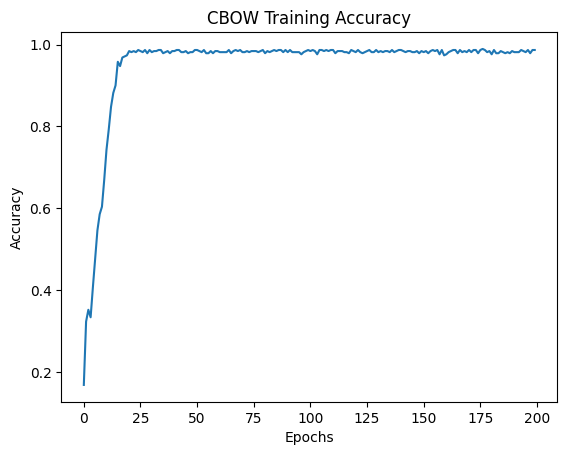

Context: ['is', 'an', 'point', 'of']
Actual Word: important
Predicted Word: important


In [9]:
# 1. Import libraries
import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical

# 2. Sample corpus
text = """The speed of transmission is an important point of difference between the two viruses.
Influenza has a shorter median incubation period and a shorter serial interval than COVID-19.
The serial interval for COVID-19 is estimated to be 5-6 days, while for influenza it is 3 days.
This means influenza can spread faster than COVID-19.
Transmission before the appearance of symptoms is called pre-symptomatic transmission.
The reproductive number is the number of secondary infections generated from one infected individual."""

# 3. Preprocessing
text = text.lower()
text = re.sub(r'[^a-z ]', ' ', text)
words = text.split()

# Repeat corpus
words = words * 5
print(words)
# 4. Create vocabulary
vocab = sorted(set(words))
word_to_id = {w:i for i, w in enumerate(vocab)}
id_to_word = {i:w for w, i in word_to_id.items()}

# 5. Generate context-target pairs
window = 2
X = []
y = []

for i in range(window, len(words)-window):
    context = [word_to_id[words[i-2]],
               word_to_id[words[i-1]],
               word_to_id[words[i+1]],
               word_to_id[words[i+2]]]

    X.append(context)
    y.append(word_to_id[words[i]])

X = np.array(X)
y = to_categorical(y, num_classes=len(vocab))

# 6. Build CBOW model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(len(vocab), 50),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(len(vocab), activation="softmax")
])

# 7. Compile model
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

# 8. Train model
history = model.fit(X, y, epochs=200, batch_size=4, verbose=0)

print("Training Loss:", history.history["loss"][-1])
print("Training Accuracy:", history.history["accuracy"][-1])

# 9. Plot accuracy
plt.plot(history.history["accuracy"])
plt.title("CBOW Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

# 10. Prediction function
def predict_word(context):
    ids = np.array([[word_to_id[w] for w in context]])
    prediction = model.predict(ids, verbose=0)
    index = np.argmax(prediction)
    return id_to_word[index]

# 11. Test prediction
context = ["is", "an", "point", "of"]

print("Context:", context)
print("Actual Word: important")
print("Predicted Word:", predict_word(context))

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

# 2. Load dataset
data = pd.read_csv("ecg.csv")

data.columns = [f'c{i}' for i in range(data.shape[1]-1)] + ['label']
data.columns

Index(['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9',
       ...
       'c131', 'c132', 'c133', 'c134', 'c135', 'c136', 'c137', 'c138', 'c139',
       'label'],
      dtype='object', length=141)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0094  
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0042  
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0030  
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0021
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0019  
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0018  
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0017  
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0016  
Epoch 9/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0015  
Epoch 10/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0013  
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 663us/step
Anomalies: 2195
Anomalies: 2195
Reconstruction Loss: 0.00543014844879508
Accuracy: 0.9647788673203922


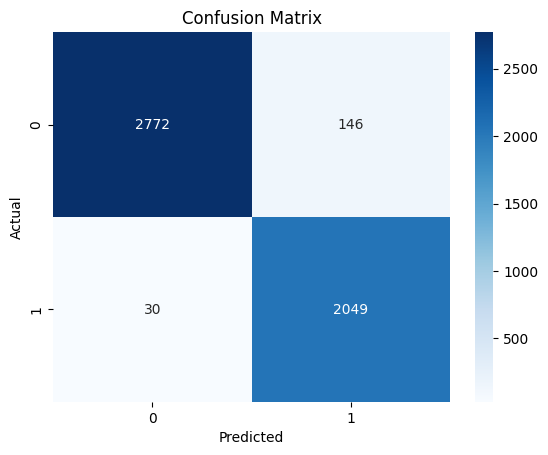

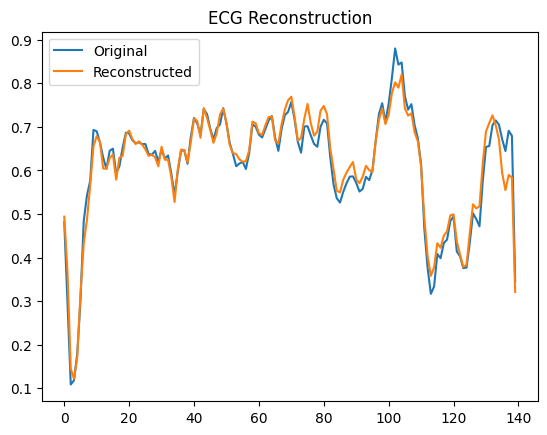

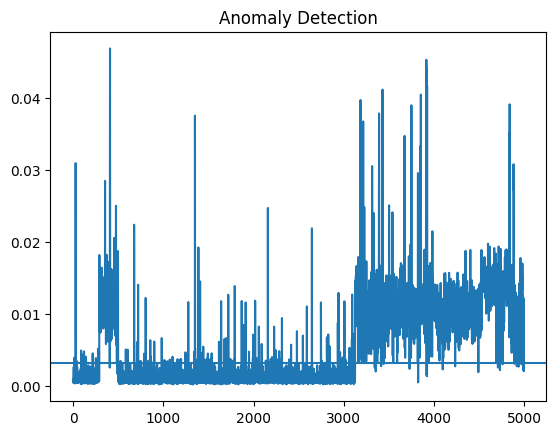

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# 2. Load dataset
data = pd.read_csv("ecg.csv")

data.columns = [f'c{i}' for i in range(data.shape[1]-1)] + ['label']
data.columns
X = data.drop("label", axis=1).values
y = data["label"]

# 3. Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 4. Separate normal and test data
X_train = X[y == 1]
X_test = X

# 5. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(X.shape[1], activation="sigmoid")
])

# 6. Compile model
model.compile(optimizer="adam", loss="mse")

# 7. Train model
model.fit(X_train, X_train, epochs=10, batch_size=32)

# 8. Calculate reconstruction error
reconstructed = model.predict(X_test)
error = np.mean((X_test - reconstructed)**2, axis=1)

threshold = np.percentile(
    np.mean((X_train - model.predict(X_train))**2, axis=1), 95
)


# 9. Detect anomalies
pred = error > threshold

print("Anomalies:", np.sum(pred))

# 10. Evaluate model
loss = model.evaluate(X_test, X_test, verbose=0)
print("Reconstruction Loss:", loss)

# Actual labels: 1 = Normal, 0 = Abnormal
y_actual = (y != 1).astype(int)
y_pred = pred.astype(int)

print("Accuracy:", accuracy_score(y_actual, y_pred))

cm = confusion_matrix(y_actual, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 10. Display ECG signal
plt.plot(X_test[0], label="Original")
plt.plot(reconstructed[0], label="Reconstructed")
plt.legend()
plt.title("ECG Reconstruction")
plt.show()

# 11. Plot reconstruction error
plt.plot(error)
plt.axhline(threshold)
plt.title("Anomaly Detection")
plt.show()


Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0070
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 2.4342e-04
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.3092e-04
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9.8666e-05
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 7.8702e-05
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 6.4523e-05
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5.3106e-05
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 4.8276e-05
Epoch 9/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 4.2171e-05
Epoch 10/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 3.9861e-05
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Anomalies: 500


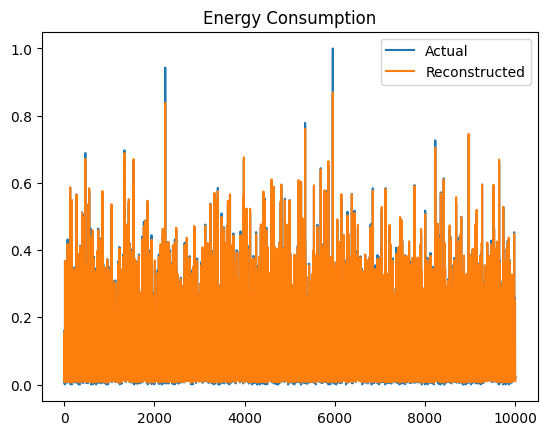

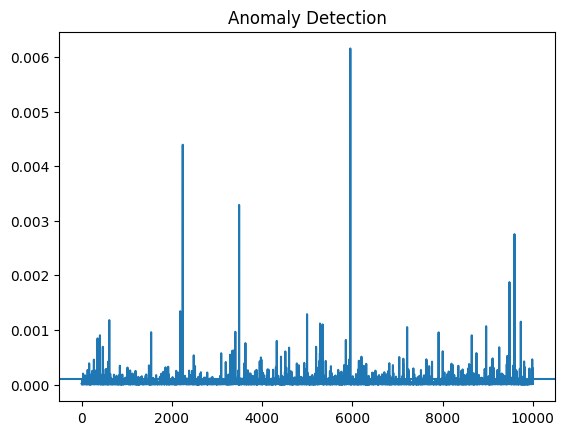

In [1]:

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# 2. Load dataset
# 2. Load dataset
data = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"]
)

# Select numerical columns and remove missing values
data = data.select_dtypes(include="number").dropna()

# Take 50,000 rows for faster training
data = data.sample(n=50000, random_state=42)

# 3. Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(data)

# 4. Split dataset
X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

# 5. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(X.shape[1], activation="sigmoid")
])

# 6. Compile model
model.compile(optimizer="adam", loss="mse")

# 7. Train model
model.fit(X_train, X_train, epochs=10, batch_size=32)

# 8. Reconstruction error
reconstructed = model.predict(X_test)
error = np.mean((X_test - reconstructed)**2, axis=1)

threshold = np.percentile(error, 95)

# 9. Detect anomalies
pred = error > threshold
print("Anomalies:", np.sum(pred))

# 10. Plot actual and reconstructed values
plt.plot(X_test[:,0], label="Actual")
plt.plot(reconstructed[:,0], label="Reconstructed")
plt.legend()
plt.title("Energy Consumption")
plt.show()

# 11. Plot errors
plt.plot(error)
plt.axhline(threshold)
plt.title("Anomaly Detection")
plt.show()


Epoch 1/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 8s 833us/step - loss: 9.3333e-04
Epoch 2/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 8s 843us/step - loss: 3.9382e-04
Epoch 3/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 839us/step - loss: 3.3534e-04
Epoch 4/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 8s 948us/step - loss: 3.0050e-04
Epoch 5/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 8s 914us/step - loss: 2.8764e-04
Epoch 6/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 834us/step - loss: 2.7403e-04
Epoch 7/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 835us/step - loss: 2.5949e-04
Epoch 8/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 838us/step - loss: 2.4989e-04
Epoch 9/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 835us/step - loss: 2.2700e-04
Epoch 10/10
8885/8885 ━━━━━━━━━━━━━━━━━━━━ 7s 837us/step - loss: 1.8082e-04
Threshold: 0.00043946375483593255
Detected Fraud: 14642
Accuracy: 0.9498537606168388

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    284315
           1       0.03      0.

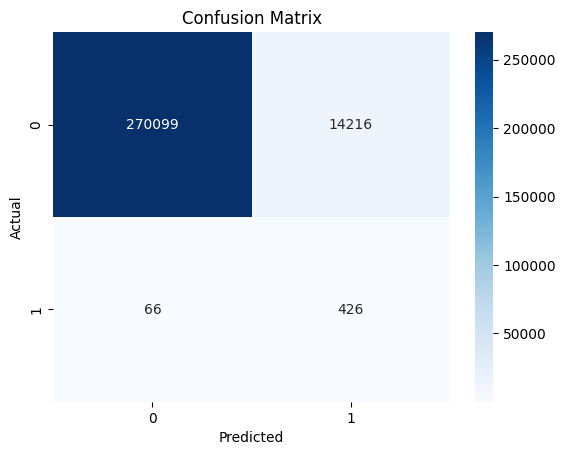

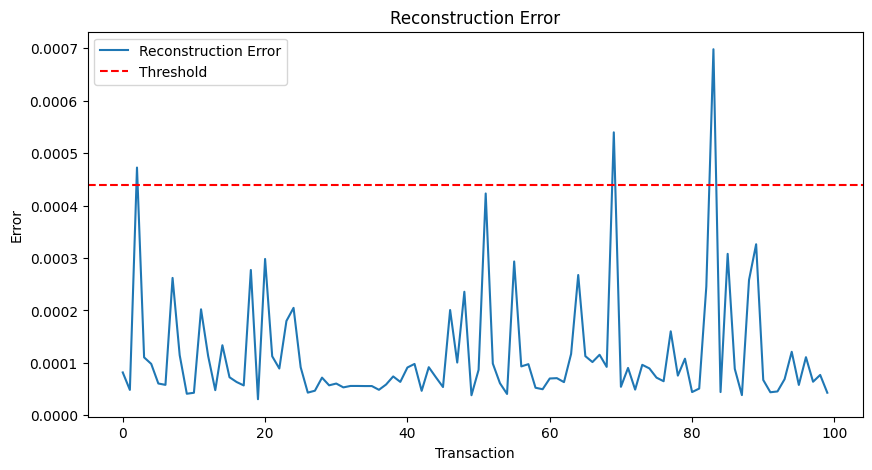

In [24]:

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 2. Load dataset
data = pd.read_csv("creditcard.csv")

X = data.drop("Class", axis=1).values
y = data["Class"].values

# 3. Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 4. Separate normal training data and test data
X_train = X[y == 0]

X_test = X
y_test = y

# 5. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(X.shape[1], activation="sigmoid")
])

# 6. Compile model
model.compile(optimizer="adam", loss="mse")

# 7. Train model using normal transactions only
model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=32,
    shuffle=True,
    verbose=1
)

# 8. Calculate reconstruction error
reconstructed = model.predict(X_test, verbose=0)

error = np.mean((X_test - reconstructed) ** 2, axis=1)

# Calculate threshold using normal training data
train_reconstructed = model.predict(X_train, verbose=0)

train_error = np.mean(
    (X_train - train_reconstructed) ** 2,
    axis=1
)

threshold = np.percentile(train_error, 95)

print("Threshold:", threshold)

# 9. Detect fraud
y_pred = (error > threshold).astype(int)

print("Detected Fraud:", np.sum(y_pred))

# 10. Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 11. Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 12. Plot reconstruction error
plt.figure(figsize=(10, 5))

plt.plot(error[:100], label="Reconstruction Error")
plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.title("Reconstruction Error")
plt.xlabel("Transaction")
plt.ylabel("Error")
plt.legend()
plt.show()
